# 06 — Limiarização, segmentação e componentes conectados

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 06/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 06/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor.


### Materiais complementares

- [Guia Técnico](./reference_materials/06_limiarizacao_segmentacao_contornos.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_limiarizacao_segmentacao_contornos.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Segmentar objetos e extrair medidas geométricas com critérios explícitos.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Segmentação gera rótulos ou máscaras para regiões da imagem. Otsu escolhe limiar maximizando separabilidade entre classes de intensidade; funciona pior quando iluminação varia espacialmente. Componentes conectados permitem contagem, área e caixas delimitadoras. Avaliar segmentação exige métricas como IoU e Dice com máscara de referência.

### Conceito matemático

$$IoU(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
from skimage.data import coins
from skimage.filters import threshold_otsu
from skimage.measure import label,regionprops
from skimage.morphology import remove_small_objects
img=coins();binary=img>threshold_otsu(img)
binary=remove_small_objects(binary,max_size=59)
regions=regionprops(label(binary))
print('componentes:',len(regions),'maiores áreas:',sorted([r.area for r in regions],reverse=True)[:5])

componentes: 24 maiores áreas: [np.float64(8755.0), np.float64(3054.0), np.float64(2459.0), np.float64(2099.0), np.float64(1954.0)]


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

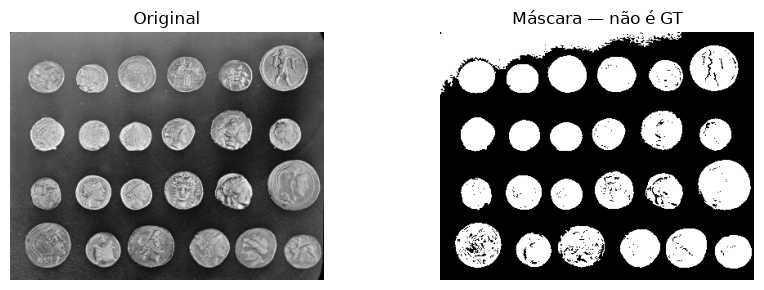

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(9,3))
ax[0].imshow(img,cmap='gray');ax[0].set_title('Original')
ax[1].imshow(binary,cmap='gray');ax[1].set_title('Máscara — não é GT')
for a in ax:a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

O número de componentes não equivale necessariamente ao número de moedas; objetos unidos e reflexos quebram essa hipótese.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Se uma predição tem 40 pixels de interseção e 60 de união com o gabarito, qual IoU?

**Resolução comentada:** 40/60 = 0,667.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Não interpretar máscaras automáticas como verdade-terreno.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Segmentar objetos e extrair medidas geométricas com critérios explícitos.
- **Mecanismo:** Segmentação gera rótulos ou máscaras para regiões da imagem.
- **Equação:** $IoU(A,B)=\frac{|A\cap B|}{|A\cup B|}$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** componentes e topologia. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **componentes e topologia** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Laboratório adicional — Contagem de componentes e efeito do limiar

Experimento independente do estado das células anteriores. Use-o como verificação e explique seus limites; resultados em conjuntos sintéticos não são estimativas de desempenho real.

In [3]:
import numpy as np
from skimage.measure import label
x=np.zeros((8,8),dtype=bool);x[1:3,1:3]=1;x[5:7,5:7]=1
componentes=label(x,connectivity=1)
print('Objetos separados:',int(componentes.max()))
assert componentes.max()==2

Objetos separados: 2


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **componentes e topologia** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
